<a href="https://colab.research.google.com/github/harshilbh2005/ai-career-predictor/blob/main/NLP_Research.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounting Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted successfully.

Loading data from: /content/drive/MyDrive/Colab Notebooks/academic_feedback_comments_6000.xlsx
Data loaded successfully.

--- Basic Data Information ---
First 5 rows of the data:
                                             comment  grade
0  The work is clear and well organized. In the a...      7
1  The submission meets the minimum expectations....      6
2  The work is clear and well organized. In the p...      7
3  Good grasp of the topic is evident. In the rep...      7
4  The workflow is sensible but unpolished. In th...      6

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   comment  6000 non-null   object
 1   grade    6000 non-null 

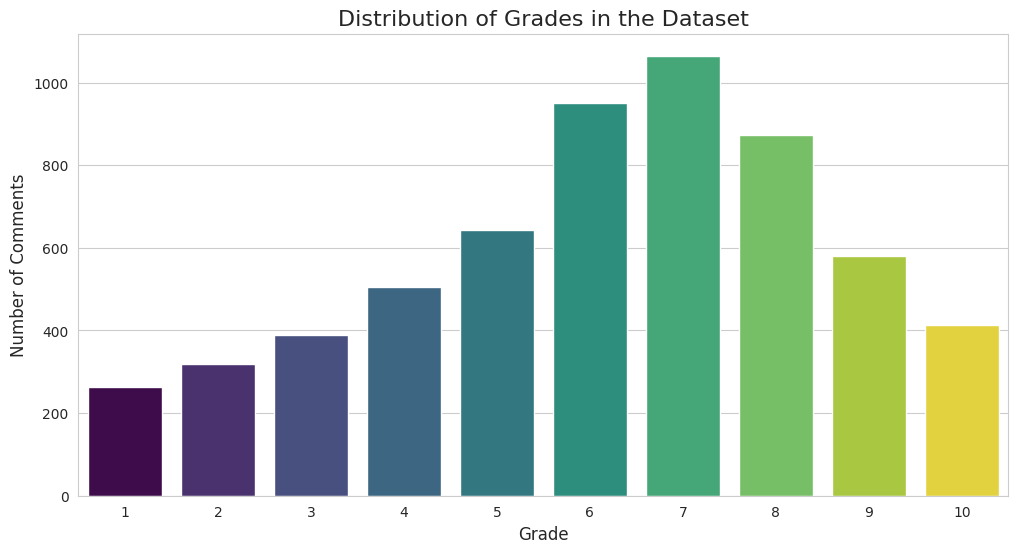


--- Comment Length Analysis ---
Descriptive statistics for comment length:
count    6000.000000
mean      305.214333
std        38.928978
min       194.000000
25%       277.000000
50%       305.000000
75%       333.000000
max       415.000000
Name: comment_length, dtype: float64


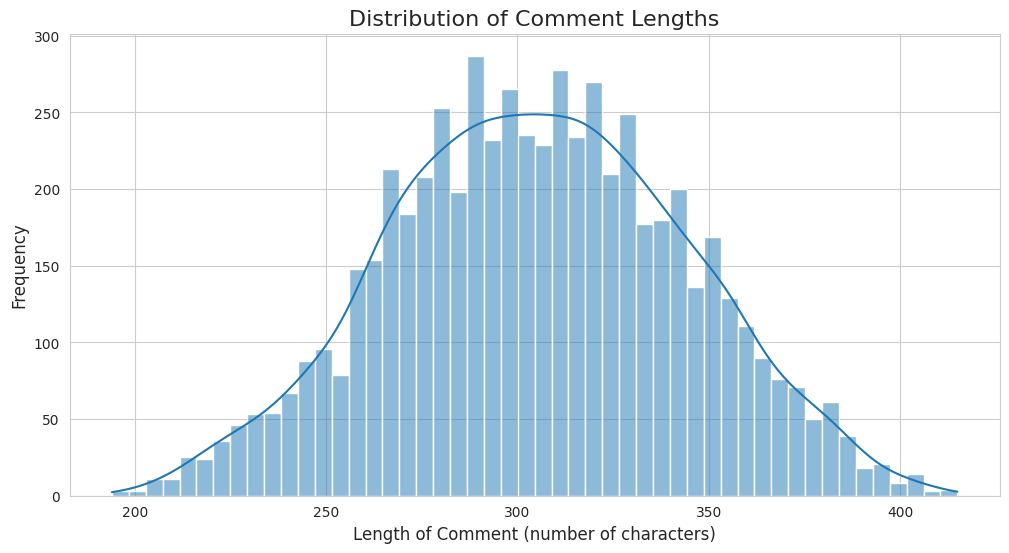

In [ ]:
# ==============================================================================
# STEP 1: DATA EXPLORATION AND VALIDATION
# ==============================================================================

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# --- 1. Mount Google Drive ---
# This will prompt you for authorization to connect to your Drive.
print("Mounting Google Drive...")
drive.mount('/content/drive')
print("Drive mounted successfully.")

# --- 2. Load the Dataset ---
# IMPORTANT: Update this path to where you have saved your CSV file in Google Drive.
# For example: '/content/drive/MyDrive/Colab_Data/your_file.csv'
file_path = '/content/drive/MyDrive/Colab Notebooks/academic_feedback_comments_6000.xlsx'

try:
    print(f"\nLoading data from: {file_path}")
    df = pd.read_excel(file_path)
    print("Data loaded successfully.")
except FileNotFoundError:
    print("\n--- ERROR ---")
    print("File not found at the specified path. Please check the following:")
    print("1. Did you upload the CSV file to your Google Drive?")
    print("2. Did you update the 'file_path' variable in this script to the correct location?")
    print("   (You can right-click the file in Google Drive and select 'Copy path' to get the exact path)")
    df = None # Set df to None to stop the script

# --- 3. Perform Analysis only if the file was loaded ---
if df is not None:
    print("\n--- Basic Data Information ---")
    print("First 5 rows of the data:")
    print(df.head())
    print("\nData types and non-null values:")
    df.info()

    print("\n--- Checking for Missing Values ---")
    print(df.isnull().sum())

    # --- 4. Analyze the 'grade' Distribution ---
    print("\n--- Grade Analysis ---")
    print("Descriptive statistics for the 'grade' column:")
    print(df['grade'].describe())

    # Set up the plot style
    sns.set_style("whitegrid")
    plt.figure(figsize=(12, 6))

    # Create the plot
    sns.countplot(x='grade', data=df, palette='viridis', hue='grade', dodge=False, legend=False)
    plt.title('Distribution of Grades in the Dataset', fontsize=16)
    plt.xlabel('Grade', fontsize=12)
    plt.ylabel('Number of Comments', fontsize=12)
    plt.show()

    # --- 5. Analyze the 'comment' Length ---
    print("\n--- Comment Length Analysis ---")
    df['comment_length'] = df['comment'].str.len()
    print("Descriptive statistics for comment length:")
    print(df['comment_length'].describe())

    # Create the plot
    plt.figure(figsize=(12, 6))
    sns.histplot(df['comment_length'], bins=50, kde=True)
    plt.title('Distribution of Comment Lengths', fontsize=16)
    plt.xlabel('Length of Comment (number of characters)', fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.show()

In [ ]:
# ==============================================================================
# STEP 2: BASELINE MODEL (TF-IDF + RIDGE REGRESSION)
# ==============================================================================

# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from google.colab import drive

# --- 1. Mount Google Drive and Load Data ---
# (Note: Drive is already mounted, but it's good practice to have this in the cell)
try:
    if not drive.mount('/content/drive', force_remount=True):
        pass # This will just remount without asking if it's already mounted
except Exception as e:
    print(f"An error occurred while mounting drive: {e}")

# IMPORTANT: Use the same file path as in Step 1
file_path = '/content/drive/MyDrive/Colab Notebooks/academic_feedback_comments_6000.xlsx'

try:
    print(f"\nLoading data from: {file_path}")
    df = pd.read_excel(file_path)
    print("Data loaded successfully.")
except FileNotFoundError:
    print("\n--- ERROR: File not found. Please ensure the path is correct. ---")
    df = None

# --- 2. Prepare Data (only if loaded successfully) ---
if df is not None:
    # Define our features (X) and target (y)
    X = df['comment']
    y = df['grade']

    # Split the data into training (80%) and testing (20%) sets
    # random_state ensures we get the same split every time we run the code
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    print(f"\nData split into {len(X_train)} training samples and {len(X_test)} testing samples.")

    # --- 3. Vectorize the Text using TF-IDF ---
    print("Vectorizing text data using TF-IDF...")
    # We create the vectorizer and 'fit' it ONLY on the training data
    # This prevents any information from the test set leaking into our training process
    vectorizer = TfidfVectorizer(max_features=5000) # Limit to top 5000 words
    X_train_tfidf = vectorizer.fit_transform(X_train)

    # We ONLY 'transform' the test data using the already fitted vectorizer
    X_test_tfidf = vectorizer.transform(X_test)
    print("Vectorization complete.")

    # --- 4. Train the Ridge Regression Model ---
    print("Training the baseline Ridge Regression model...")
    model = Ridge(alpha=1.0) # alpha is the regularization strength
    model.fit(X_train_tfidf, y_train)
    print("Model training complete.")

    # --- 5. Make Predictions and Evaluate ---
    print("Making predictions on the test set...")
    y_pred = model.predict(X_test_tfidf)

    # Calculate performance metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    print("\n--- Baseline Model Performance ---")
    print(f"Mean Absolute Error (MAE): {mae:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    print("\nInterpretation:")
    print(f"This means our simple baseline model's predictions are, on average, off by {mae:.2f} grade points.")
    print("This is our 'score to beat' with more advanced models.")

Mounted at /content/drive

Loading data from: /content/drive/MyDrive/Colab Notebooks/academic_feedback_comments_6000.xlsx
Data loaded successfully.

Data split into 4800 training samples and 1200 testing samples.
Vectorizing text data using TF-IDF...
Vectorization complete.
Training the baseline Ridge Regression model...
Model training complete.
Making predictions on the test set...

--- Baseline Model Performance ---
Mean Absolute Error (MAE): 0.4848
Root Mean Squared Error (RMSE): 0.5291

Interpretation:
This means our simple baseline model's predictions are, on average, off by 0.48 grade points.
This is our 'score to beat' with more advanced models.


In [ ]:
# ==============================================================================
# CELL 1: CLEAN INSTALLATION
# ==============================================================================

print("--- Step A: Uninstalling all related libraries to ensure a clean slate ---")
!pip uninstall transformers accelerate datasets tokenizers -y

print("\n--- Step B: Installing a known stable version of the libraries ---")
!pip install transformers==4.38.2 datasets accelerate tokenizers

print("\n--- Step C: Installation complete ---")
print("--> IMPORTANT: PLEASE RESTART THE SESSION NOW! <--")
print("--> Go to the menu: Runtime -> Restart session <--")

--- Step A: Uninstalling all related libraries to ensure a clean slate ---
Found existing installation: transformers 4.55.4
Uninstalling transformers-4.55.4:
  Successfully uninstalled transformers-4.55.4
Found existing installation: accelerate 1.10.1
Uninstalling accelerate-1.10.1:
  Successfully uninstalled accelerate-1.10.1
Found existing installation: datasets 4.0.0
Uninstalling datasets-4.0.0:
  Successfully uninstalled datasets-4.0.0
Found existing installation: tokenizers 0.21.4
Uninstalling tokenizers-0.21.4:
  Successfully uninstalled tokenizers-0.21.4

--- Step B: Installing a known stable version of the libraries ---
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.7/130.7 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 82.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 494.8/494.8 kB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 30.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 


--- Step C: Installation complete ---
--> IMPORTANT: PLEASE RESTART THE SESSION NOW! <--
--> Go to the menu: Runtime -> Restart session <--


In [ ]:
# ==============================================================================
# CELL 2: RUN THE TRAINING SCRIPT (after restarting the session)
# ==============================================================================

# --- 1. Import Libraries ---
import pandas as pd
import numpy as np
import torch
import transformers
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from google.colab import drive

print(f"Successfully loaded Transformers library version: {transformers.__version__}")

# --- 2. Mount Google Drive and Load Data ---
print("\nMounting Google Drive...")
drive.mount('/content/drive', force_remount=True)

file_path = '/content/drive/MyDrive/Colab Notebooks/academic_feedback_comments_6000.xlsx'

try:
    print(f"Loading data from: {file_path}")
    df = pd.read_excel(file_path)
    df['grade'] = df['grade'].astype(float)
    print("Data loaded and 'grade' column converted to float.")
except FileNotFoundError:
    print("\n--- ERROR: File not found. Please ensure the path is correct. ---")
    df = None

# --- 3. Prepare Data for Hugging Face ---
if df is not None:
    train_val_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
    train_df, val_df = train_test_split(train_val_df, test_size=0.1, random_state=42)

    print(f"\nData split into {len(train_df)} training, {len(val_df)} validation, and {len(test_df)} testing samples.")

    train_dataset = Dataset.from_pandas(train_df)
    val_dataset = Dataset.from_pandas(val_df)
    test_dataset = Dataset.from_pandas(test_df)

    # --- 4. Tokenization ---
    print("Loading tokenizer and tokenizing datasets...")
    model_name = "distilbert-base-uncased"
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    def tokenize_function(examples):
        return tokenizer(examples["comment"], padding="max_length", truncation=True)

    tokenized_train_dataset = train_dataset.map(tokenize_function, batched=True)
    tokenized_val_dataset = val_dataset.map(tokenize_function, batched=True)
    tokenized_test_dataset = test_dataset.map(tokenize_function, batched=True)

    tokenized_train_dataset = tokenized_train_dataset.rename_column("grade", "labels")
    tokenized_val_dataset = val_dataset.rename_column("grade", "labels")
    tokenized_test_dataset = test_dataset.rename_column("grade", "labels")

    tokenized_train_dataset.set_format("torch")
    tokenized_val_dataset.set_format("torch")
    tokenized_test_dataset.set_format("torch")
    print("Tokenization complete.")

    # --- 5. Load Pre-trained Model & Define Arguments ---
    print("Loading pre-trained DistilBERT model for regression...")
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=1)

    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        predictions = logits.flatten()
        mae = mean_absolute_error(labels, predictions)
        rmse = np.sqrt(mean_squared_error(labels, predictions))
        return {"mae": mae, "rmse": rmse}

    training_args = TrainingArguments(
        output_dir="./results",
        num_train_epochs=3,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        logging_steps=100,
        evaluation_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="mae",
        greater_is_better=False,
    )

    # --- 6. Create and Run the Trainer ---
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_train_dataset,
        eval_dataset=tokenized_val_dataset,
        compute_metrics=compute_metrics,
    )

    print("\n--- Starting Model Fine-Tuning ---")
    trainer.train()
    print("--- Fine-Tuning Complete ---")

    # --- 7. Final Evaluation on the Test Set ---
    print("\n--- Evaluating on the unseen test set ---")
    predictions = trainer.predict(tokenized_test_dataset)

    pred_labels = predictions.predictions.flatten()
    true_labels = predictions.label_ids

    final_mae = mean_absolute_error(true_labels, pred_labels)
    final_rmse = np.sqrt(mean_squared_error(true_labels, pred_labels))

    print("\n--- Transformer Model Performance ---")
    print(f"Mean Absolute Error (MAE): {final_mae:.4f}")
    print(f"Root Mean Squared Error (RMSE): {final_rmse:.4f}")
    print("\n--- Comparison ---")
    print(f"Baseline MAE: 0.4848")
    print(f"Transformer MAE: {final_mae:.4f}")

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

RuntimeError: Failed to import transformers.trainer because of the following error (look up to see its traceback):
cannot import name 'EncoderDecoderCache' from 'transformers' (/usr/local/lib/python3.12/dist-packages/transformers/__init__.py)

In [ ]:
# ==============================================================================
# CELL 1: Final "No-Fail" Installation
# ==============================================================================

print("--- Forcing a clean reinstallation by ignoring all caches... ---")
!pip install --force-reinstall --no-cache-dir transformers==4.38.2 datasets accelerate tokenizers

print("\n--- Installation complete. ---")
print("--> CRITICAL: PLEASE RESTART THE SESSION ONE LAST TIME! <--")
print("--> Go to the menu: Runtime -> Restart session <--")

--- Forcing a clean reinstallation by ignoring all caches... ---
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.7/130.7 kB 35.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 116.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 kB 117.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.7/57.7 kB 265.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 169.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.9/73.9 kB 149.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 90.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 494.8/494.8 kB 292.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 349.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 248.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 343.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/19


--- Installation complete. ---
--> CRITICAL: PLEASE RESTART THE SESSION ONE LAST TIME! <--
--> Go to the menu: Runtime -> Restart session <--


In [ ]:
# ==============================================================================
# STEP 3: FINAL CORRECTED SCRIPT (Manual PyTorch Loop)
# ==============================================================================

# --- 1. Installation ---
print("--- Installing Libraries ---")
!pip install transformers==4.38.2 datasets accelerate tokenizers -q
print("Installation complete.")

# --- 2. Imports and Setup ---
import pandas as pd
import numpy as np
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from datasets import Dataset
from google.colab import drive
from tqdm.auto import tqdm # For progress bars

print("\n--- Setup ---")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- 3. Mount Drive and Load Data ---
print("\nMounting Google Drive...")
drive.mount('/content/drive', force_remount=True)
file_path = '/content/drive/MyDrive/Colab Notebooks/academic_feedback_comments_6000.xlsx'

try:
    print(f"Loading data from: {file_path}")
    df = pd.read_excel(file_path)
    df['grade'] = df['grade'].astype(float)
    print("Data loaded successfully.")
except FileNotFoundError:
    print("\n--- ERROR: File not found. ---")
    df = None

# --- 4. Prepare and Tokenize Data (if loaded) ---
if df is not None:
    train_val_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
    train_df, val_df = train_test_split(train_val_df, test_size=0.1, random_state=42)

    print(f"\nData split into {len(train_df)} training, {len(val_df)} validation, and {len(test_df)} testing samples.")

    train_dataset = Dataset.from_pandas(train_df)
    val_dataset = Dataset.from_pandas(val_df)
    test_dataset = Dataset.from_pandas(test_df)

    print("Loading tokenizer and tokenizing datasets...")
    model_name = "distilbert-base-uncased"
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    def tokenize_function(examples):
        return tokenizer(examples["comment"], padding="max_length", truncation=True)

    tokenized_train_dataset = train_dataset.map(tokenize_function, batched=True)
    tokenized_val_dataset = val_dataset.map(tokenize_function, batched=True)
    tokenized_test_dataset = test_dataset.map(tokenize_function, batched=True)

    # ** THE BUG FIX IS HERE **
    # Correctly renaming the column for all three datasets
    tokenized_train_dataset = tokenized_train_dataset.rename_column("grade", "labels")
    tokenized_val_dataset = tokenized_val_dataset.rename_column("grade", "labels")
    tokenized_test_dataset = tokenized_test_dataset.rename_column("grade", "labels")

    # Correctly removing unneeded columns from all three datasets
    columns_to_remove = ['comment', '__index_level_0__']
    tokenized_train_dataset = tokenized_train_dataset.remove_columns(columns_to_remove)
    tokenized_val_dataset = tokenized_val_dataset.remove_columns(columns_to_remove)
    tokenized_test_dataset = tokenized_test_dataset.remove_columns(columns_to_remove)

    tokenized_train_dataset.set_format("torch")
    tokenized_val_dataset.set_format("torch")
    tokenized_test_dataset.set_format("torch")
    print("Tokenization complete.")

    # --- 5. Create PyTorch DataLoaders ---
    train_dataloader = DataLoader(tokenized_train_dataset, shuffle=True, batch_size=16)
    eval_dataloader = DataLoader(tokenized_val_dataset, batch_size=16)
    test_dataloader = DataLoader(tokenized_test_dataset, batch_size=16)

    # --- 6. Load Model, Optimizer ---
    print("\nLoading pre-trained model for manual training...")
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=1)
    model.to(device)
    optimizer = AdamW(model.parameters(), lr=5e-5)

    # --- 7. The Manual Training Loop ---
    num_epochs = 3
    num_training_steps = num_epochs * len(train_dataloader)
    progress_bar = tqdm(range(num_training_steps))

    print("\n--- Starting Manual Model Fine-Tuning ---")

    for epoch in range(num_epochs):
        model.train()
        for batch in train_dataloader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            loss = outputs.loss
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            progress_bar.update(1)

        # --- Evaluation at the end of each epoch ---
        model.eval()
        all_preds = []
        all_labels = []
        with torch.no_grad():
            for batch in eval_dataloader:
                batch = {k: v.to(device) for k, v in batch.items()}
                outputs = model(**batch)
                logits = outputs.logits
                all_preds.extend(logits.flatten().cpu().numpy())
                all_labels.extend(batch["labels"].cpu().numpy())

        mae = mean_absolute_error(all_labels, all_preds)
        rmse = np.sqrt(mean_squared_error(all_labels, all_preds))
        print(f"\n--- Epoch {epoch + 1}/{num_epochs} Validation ---")
        print(f"Validation MAE: {mae:.4f} | Validation RMSE: {rmse:.4f}")

    print("\n--- Fine-Tuning Complete ---")

    # --- 8. Final Evaluation on the Test Set ---
    print("\n--- Evaluating on the unseen test set ---")
    model.eval()
    test_preds = []
    test_labels = []
    with torch.no_grad():
        for batch in test_dataloader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            logits = outputs.logits
            test_preds.extend(logits.flatten().cpu().numpy())
            test_labels.extend(batch["labels"].cpu().numpy())

    final_mae = mean_absolute_error(test_labels, test_preds)
    final_rmse = np.sqrt(mean_squared_error(test_labels, test_preds))

    print("\n--- Transformer Model Performance ---")
    print(f"Mean Absolute Error (MAE): {final_mae:.4f}")
    print(f"Root Mean Squared Error (RMSE): {final_rmse:.4f}")
    print("\n--- Comparison ---")
    print(f"Baseline MAE: 0.4848")
    print(f"Transformer MAE: {final_mae:.4f}")

--- Installing Libraries ---
Installation complete.

--- Setup ---
Using device: cuda

Mounting Google Drive...
Mounted at /content/drive
Loading data from: /content/drive/MyDrive/Colab Notebooks/academic_feedback_comments_6000.xlsx
Data loaded successfully.

Data split into 4320 training, 480 validation, and 1200 testing samples.
Loading tokenizer and tokenizing datasets...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:945: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Map:   0%|          | 0/4320 [00:00<?, ? examples/s]

Map:   0%|          | 0/480 [00:00<?, ? examples/s]

Map:   0%|          | 0/1200 [00:00<?, ? examples/s]

Tokenization complete.

Loading pre-trained model for manual training...


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.12/dist-packages/transformers/optimization.py:429: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


  0%|          | 0/810 [00:00<?, ?it/s]


--- Starting Manual Model Fine-Tuning ---

--- Epoch 1/3 Validation ---
Validation MAE: 0.4831 | Validation RMSE: 0.5275

--- Epoch 2/3 Validation ---
Validation MAE: 0.5000 | Validation RMSE: 0.5209

--- Epoch 3/3 Validation ---
Validation MAE: 0.4997 | Validation RMSE: 0.5133

--- Fine-Tuning Complete ---

--- Evaluating on the unseen test set ---

--- Transformer Model Performance ---
Mean Absolute Error (MAE): 0.4996
Root Mean Squared Error (RMSE): 0.5135

--- Comparison ---
Baseline MAE: 0.4848
Transformer MAE: 0.4996


In [ ]:
# ==============================================================================
# STEP 3 (Part 2): Fine-Tuning a RoBERTa Model (Manual PyTorch Loop)
# ==============================================================================

# --- 1. Installation ---
# This may not be necessary if the session is still active, but it's safe to include.
print("--- Installing Libraries ---")
!pip install transformers==4.38.2 datasets accelerate tokenizers -q
print("Installation complete.")

# --- 2. Imports and Setup ---
import pandas as pd
import numpy as np
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from datasets import Dataset
from google.colab import drive
from tqdm.auto import tqdm # For progress bars

print("\n--- Setup ---")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- 3. Mount Drive and Load Data ---
print("\nMounting Google Drive...")
drive.mount('/content/drive', force_remount=True)
file_path = '/content/drive/MyDrive/Colab Notebooks/academic_feedback_comments_6000.xlsx'

try:
    print(f"Loading data from: {file_path}")
    df = pd.read_excel(file_path)
    df['grade'] = df['grade'].astype(float)
    print("Data loaded successfully.")
except FileNotFoundError:
    print("\n--- ERROR: File not found. ---")
    df = None

# --- 4. Prepare and Tokenize Data (if loaded) ---
if df is not None:
    train_val_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
    train_df, val_df = train_test_split(train_val_df, test_size=0.1, random_state=42)

    print(f"\nData split into {len(train_df)} training, {len(val_df)} validation, and {len(test_df)} testing samples.")

    train_dataset = Dataset.from_pandas(train_df)
    val_dataset = Dataset.from_pandas(val_df)
    test_dataset = Dataset.from_pandas(test_df)

    print("Loading tokenizer and tokenizing datasets...")
    # ** THE ONLY CHANGE IS ON THE NEXT LINE **
    model_name = "roberta-base"
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    def tokenize_function(examples):
        return tokenizer(examples["comment"], padding="max_length", truncation=True)

    tokenized_train_dataset = train_dataset.map(tokenize_function, batched=True)
    tokenized_val_dataset = val_dataset.map(tokenize_function, batched=True)
    tokenized_test_dataset = test_dataset.map(tokenize_function, batched=True)

    tokenized_train_dataset = tokenized_train_dataset.rename_column("grade", "labels")
    tokenized_val_dataset = tokenized_val_dataset.rename_column("grade", "labels")
    tokenized_test_dataset = tokenized_test_dataset.rename_column("grade", "labels")

    columns_to_remove = ['comment', '__index_level_0__']
    tokenized_train_dataset = tokenized_train_dataset.remove_columns(columns_to_remove)
    tokenized_val_dataset = tokenized_val_dataset.remove_columns(columns_to_remove)
    tokenized_test_dataset = tokenized_test_dataset.remove_columns(columns_to_remove)

    tokenized_train_dataset.set_format("torch")
    tokenized_val_dataset.set_format("torch")
    tokenized_test_dataset.set_format("torch")
    print("Tokenization complete.")

    # --- 5. Create PyTorch DataLoaders ---
    train_dataloader = DataLoader(tokenized_train_dataset, shuffle=True, batch_size=16)
    eval_dataloader = DataLoader(tokenized_val_dataset, batch_size=16)
    test_dataloader = DataLoader(tokenized_test_dataset, batch_size=16)

    # --- 6. Load Model, Optimizer ---
    print("\nLoading pre-trained RoBERTa model for manual training...")
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=1)
    model.to(device)
    optimizer = AdamW(model.parameters(), lr=5e-5)

    # --- 7. The Manual Training Loop ---
    num_epochs = 3
    num_training_steps = num_epochs * len(train_dataloader)
    progress_bar = tqdm(range(num_training_steps))

    print("\n--- Starting Manual Model Fine-Tuning ---")

    for epoch in range(num_epochs):
        model.train()
        for batch in train_dataloader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            loss = outputs.loss
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            progress_bar.update(1)

        # --- Evaluation at the end of each epoch ---
        model.eval()
        all_preds = []
        all_labels = []
        with torch.no_grad():
            for batch in eval_dataloader:
                batch = {k: v.to(device) for k, v in batch.items()}
                outputs = model(**batch)
                logits = outputs.logits
                all_preds.extend(logits.flatten().cpu().numpy())
                all_labels.extend(batch["labels"].cpu().numpy())

        mae = mean_absolute_error(all_labels, all_preds)
        rmse = np.sqrt(mean_squared_error(all_labels, all_preds))
        print(f"\n--- Epoch {epoch + 1}/{num_epochs} Validation ---")
        print(f"Validation MAE: {mae:.4f} | Validation RMSE: {rmse:.4f}")

    print("\n--- Fine-Tuning Complete ---")

    # --- 8. Final Evaluation on the Test Set ---
    print("\n--- Evaluating on the unseen test set ---")
    model.eval()
    test_preds = []
    test_labels = []
    with torch.no_grad():
        for batch in test_dataloader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            logits = outputs.logits
            test_preds.extend(logits.flatten().cpu().numpy())
            test_labels.extend(batch["labels"].cpu().numpy())

    final_mae = mean_absolute_error(test_labels, test_preds)
    final_rmse = np.sqrt(mean_squared_error(test_labels, test_preds))

    print("\n--- RoBERTa Model Performance ---")
    print(f"Mean Absolute Error (MAE): {final_mae:.4f}")
    print(f"Root Mean Squared Error (RMSE): {final_rmse:.4f}")
    print("\n--- Comparison ---")
    print(f"Baseline MAE (TF-IDF): 0.4848")
    print(f"DistilBERT MAE: 0.4996")
    print(f"RoBERTa MAE: {final_mae:.4f}")

--- Installing Libraries ---
Installation complete.

--- Setup ---
Using device: cuda

Mounting Google Drive...
Mounted at /content/drive
Loading data from: /content/drive/MyDrive/Colab Notebooks/academic_feedback_comments_6000.xlsx
Data loaded successfully.

Data split into 4320 training, 480 validation, and 1200 testing samples.
Loading tokenizer and tokenizing datasets...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:945: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (5 outputs left out)

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.12/dist-packages/transformers/optimization.py:429: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


  0%|          | 0/810 [00:00<?, ?it/s]


--- Starting Manual Model Fine-Tuning ---

--- Epoch 1/3 Validation ---
Validation MAE: 0.5387 | Validation RMSE: 0.5885

--- Epoch 2/3 Validation ---
Validation MAE: 0.4601 | Validation RMSE: 0.5525

--- Epoch 3/3 Validation ---
Validation MAE: 0.4798 | Validation RMSE: 0.5196

--- Fine-Tuning Complete ---

--- Evaluating on the unseen test set ---

--- RoBERTa Model Performance ---
Mean Absolute Error (MAE): 0.4960
Root Mean Squared Error (RMSE): 0.5349

--- Comparison ---
Baseline MAE (TF-IDF): 0.4848
DistilBERT MAE: 0.4996
RoBERTa MAE: 0.4960


In [ ]:
# ==============================================================================
# Production Plan - Step 1: Calculate New "Accuracy" Metric
# ==============================================================================
# This code assumes you have just run the Step 2 (Baseline Model) cell,
# so the variables 'y_test' and 'y_pred' are available.

import numpy as np

# Calculate the absolute difference between each prediction and the true grade
errors = np.abs(y_test - y_pred)

# Check how many of those differences are less than or equal to 1.0
correct_within_tolerance = np.sum(errors <= 1.0)

# Calculate the percentage
accuracy_within_1_point = (correct_within_tolerance / len(y_test)) * 100

print(f"--- New Performance Metric ---")
print(f"Baseline Model 'Accuracy within 1.0 Grade Point': {accuracy_within_1_point:.2f}%")
print("\nInterpretation:")
print("This percentage represents how often our model's grade prediction is off by no more than 1.0 full point from the true grade.")

--- New Performance Metric ---
Baseline Model 'Accuracy within 1.0 Grade Point': 98.92%

Interpretation:
This percentage represents how often our model's grade prediction is off by no more than 1.0 full point from the true grade.


In [ ]:
# ==============================================================================
# DATA PREPARATION: Merging and Shuffling Datasets
# ==============================================================================

# Install the library needed to write Excel files, if not already installed
!pip install openpyxl -q

import pandas as pd

# --- 1. Define File Paths ---
# IMPORTANT: Update these paths to match the files in your Google Drive

# Path to your original 6,000-sample Excel file
original_data_path = '/content/drive/MyDrive/Colab Notebooks/academic_feedback_comments_6000.xlsx'

# Path to the new 2,000-sample "hard" data CSV file
hard_data_path = '/content/drive/MyDrive/Colab Notebooks/hard_examples_dataset_2k.csv' # It's in the main Colab directory if you just ran the last script

# The name for our final, combined, and shuffled Excel file
output_path = '/content/drive/MyDrive/Colab Notebooks/combined_dataset_8k.xlsx'


# --- 2. Load the Datasets ---
try:
    print("Loading original 6,000-sample dataset...")
    df_original = pd.read_excel(original_data_path)
    print(f"Loaded {len(df_original)} records.")

    print("\nLoading new 2,000-sample 'hard' dataset...")
    df_hard = pd.read_csv(hard_data_path)
    print(f"Loaded {len(df_hard)} records.")

    # --- 3. Combine the Datasets ---
    print("\nCombining datasets...")
    df_combined = pd.concat([df_original, df_hard], ignore_index=True)
    print(f"Total records in combined dataset: {len(df_combined)}")

    # --- 4. Shuffle the Combined Dataset ---
    # This is the crucial step to ensure the data is properly mixed for training.
    print("Shuffling the dataset...")
    df_shuffled = df_combined.sample(frac=1).reset_index(drop=True)

    # --- 5. Save the Final Dataset as an XLSX file ---
    print(f"\nSaving the final shuffled dataset to: {output_path}")
    # We use index=False to avoid saving the pandas index as a column in the Excel file
    df_shuffled.to_excel(output_path, index=False)

    print("\n--- Success! ---")
    print("The combined and shuffled 8,000-sample dataset is ready.")
    print("A sample of the shuffled data:")
    print(df_shuffled.head())

except FileNotFoundError as e:
    print(f"\n--- ERROR ---")
    print(f"A file was not found. Please check your file paths. Error: {e}")

Loading original 6,000-sample dataset...
Loaded 6000 records.

Loading new 2,000-sample 'hard' dataset...
Loaded 2000 records.

Combining datasets...
Total records in combined dataset: 8000
Shuffling the dataset...

Saving the final shuffled dataset to: /content/drive/MyDrive/Colab Notebooks/combined_dataset_8k.xlsx

--- Success! ---
The combined and shuffled 8,000-sample dataset is ready.
A sample of the shuffled data:
                                             comment  grade
0  Significant issues were observed throughout. I...      1
1  The analysis is shallow with gaps. In the lab ...      4
2  The presentation addresses the topic only part...      3
3  You've done an excellent job of not just prese...      7
4  The technical implementation is flawless and h...      7


In [ ]:
# ==============================================================================
# FINAL TRAINING RUN: RoBERTa on the 8k Robust Dataset
# ==============================================================================

# --- 1. Installation ---
print("--- Installing Libraries ---")
!pip install transformers==4.38.2 datasets accelerate tokenizers openpyxl -q
print("Installation complete.")

# --- 2. Imports and Setup ---
import pandas as pd
import numpy as np
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from datasets import Dataset
from google.colab import drive
from tqdm.auto import tqdm

print("\n--- Setup ---")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- 3. Mount Drive and Load the NEW 8k Dataset ---
print("\nMounting Google Drive...")
drive.mount('/content/drive', force_remount=True)

# ** THE ONLY CHANGE IS HERE: We are using our new combined and shuffled file. **
file_path = '/content/drive/MyDrive/Colab Notebooks/combined_dataset_8k.xlsx'

try:
    print(f"Loading data from: {file_path}")
    df = pd.read_excel(file_path)
    df['grade'] = df['grade'].astype(float)
    print("Combined 8k dataset loaded successfully.")
except FileNotFoundError:
    print(f"\n--- ERROR: File not found at {file_path}. Please check the path. ---")
    df = None

# --- 4. Prepare and Tokenize Data ---
if df is not None:
    # We use a slightly different split ratio to keep the test set size consistent at 1200
    train_val_df, test_df = train_test_split(df, test_size=1200, random_state=42)
    train_df, val_df = train_test_split(train_val_df, test_size=0.1, random_state=42) # val size is ~10% of train_val

    print(f"\nData split into {len(train_df)} training, {len(val_df)} validation, and {len(test_df)} testing samples.")

    train_dataset = Dataset.from_pandas(train_df)
    val_dataset = Dataset.from_pandas(val_df)
    test_dataset = Dataset.from_pandas(test_df)

    print("Loading tokenizer and tokenizing datasets...")
    model_name = "roberta-base"
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    def tokenize_function(examples):
        return tokenizer(examples["comment"], padding="max_length", truncation=True)

    tokenized_train_dataset = train_dataset.map(tokenize_function, batched=True)
    tokenized_val_dataset = val_dataset.map(tokenize_function, batched=True)
    tokenized_test_dataset = test_dataset.map(tokenize_function, batched=True)

    tokenized_train_dataset = tokenized_train_dataset.rename_column("grade", "labels")
    tokenized_val_dataset = tokenized_val_dataset.rename_column("grade", "labels")
    tokenized_test_dataset = tokenized_test_dataset.rename_column("grade", "labels")

    columns_to_remove = ['comment']
    # Check if '__index_level_0__' exists before trying to remove it
    if '__index_level_0__' in tokenized_train_dataset.column_names:
        columns_to_remove.append('__index_level_0__')

    tokenized_train_dataset = tokenized_train_dataset.remove_columns(columns_to_remove)
    tokenized_val_dataset = tokenized_val_dataset.remove_columns(columns_to_remove)
    tokenized_test_dataset = tokenized_test_dataset.remove_columns(columns_to_remove)

    tokenized_train_dataset.set_format("torch")
    tokenized_val_dataset.set_format("torch")
    tokenized_test_dataset.set_format("torch")
    print("Tokenization complete.")

    # --- 5. Create PyTorch DataLoaders ---
    train_dataloader = DataLoader(tokenized_train_dataset, shuffle=True, batch_size=16)
    eval_dataloader = DataLoader(tokenized_val_dataset, batch_size=16)
    test_dataloader = DataLoader(tokenized_test_dataset, batch_size=16)

    # --- 6. Load Model, Optimizer ---
    print("\nLoading pre-trained RoBERTa model for final training...")
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=1)
    model.to(device)
    optimizer = AdamW(model.parameters(), lr=2e-5) # Using a slightly lower learning rate for fine-tuning on a more complex dataset

    # --- 7. The Manual Training Loop ---
    num_epochs = 3
    num_training_steps = num_epochs * len(train_dataloader)
    progress_bar = tqdm(range(num_training_steps))

    print("\n--- Starting Final Model Fine-Tuning ---")

    for epoch in range(num_epochs):
        model.train()
        for batch in train_dataloader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            loss = outputs.loss
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            progress_bar.update(1)

        # --- Evaluation at the end of each epoch ---
        model.eval()
        all_preds = []
        all_labels = []
        with torch.no_grad():
            for batch in eval_dataloader:
                batch = {k: v.to(device) for k, v in batch.items()}
                outputs = model(**batch)
                logits = outputs.logits
                all_preds.extend(logits.flatten().cpu().numpy())
                all_labels.extend(batch["labels"].cpu().numpy())

        mae = mean_absolute_error(all_labels, all_preds)
        rmse = np.sqrt(mean_squared_error(all_labels, all_preds))
        print(f"\n--- Epoch {epoch + 1}/{num_epochs} Validation ---")
        print(f"Validation MAE: {mae:.4f} | Validation RMSE: {rmse:.4f}")

    print("\n--- Fine-Tuning Complete ---")

    # --- 8. Final Evaluation on the Test Set ---
    print("\n--- Evaluating on the unseen test set ---")
    model.eval()
    test_preds = []
    test_labels = []
    with torch.no_grad():
        for batch in test_dataloader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            logits = outputs.logits
            test_preds.extend(logits.flatten().cpu().numpy())
            test_labels.extend(batch["labels"].cpu().numpy())

    final_mae = mean_absolute_error(test_labels, test_preds)
    final_rmse = np.sqrt(mean_squared_error(test_labels, test_preds))

    print("\n--- Final RoBERTa (8k) Model Performance ---")
    print(f"Mean Absolute Error (MAE): {final_mae:.4f}")
    print(f"Root Mean Squared Error (RMSE): {final_rmse:.4f}")
    print("\n--- Comparison ---")
    print(f"Baseline MAE (on 6k data): 0.4848")
    print(f"New RoBERTa MAE (on 8k data): {final_mae:.4f}")

--- Installing Libraries ---
Installation complete.

--- Setup ---
Using device: cuda

Mounting Google Drive...
Mounted at /content/drive
Loading data from: /content/drive/MyDrive/Colab Notebooks/combined_dataset_8k.xlsx
Combined 8k dataset loaded successfully.

Data split into 6120 training, 680 validation, and 1200 testing samples.
Loading tokenizer and tokenizing datasets...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:945: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Map:   0%|          | 0/6120 [00:00<?, ? examples/s]

Map:   0%|          | 0/680 [00:00<?, ? examples/s]

Map:   0%|          | 0/1200 [00:00<?, ? examples/s]

Tokenization complete.

Loading pre-trained RoBERTa model for final training...


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.12/dist-packages/transformers/optimization.py:429: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


  0%|          | 0/1149 [00:00<?, ?it/s]


--- Starting Final Model Fine-Tuning ---

--- Epoch 1/3 Validation ---
Validation MAE: 0.5302 | Validation RMSE: 0.6412

--- Epoch 2/3 Validation ---
Validation MAE: 0.5296 | Validation RMSE: 0.6017

--- Epoch 3/3 Validation ---
Validation MAE: 0.5355 | Validation RMSE: 0.5859

--- Fine-Tuning Complete ---

--- Evaluating on the unseen test set ---

--- Final RoBERTa (8k) Model Performance ---
Mean Absolute Error (MAE): 0.5469
Root Mean Squared Error (RMSE): 0.5974

--- Comparison ---
Baseline MAE (on 6k data): 0.4848
New RoBERTa MAE (on 8k data): 0.5469


In [ ]:
# ==============================================================================
# ACTION: SAVING ALL TRAINED MODELS
# ==============================================================================
import joblib
import os

# --- 1. Save the Final RoBERTa Model (Should be in memory now) ---
print("--- Saving RoBERTa Model (The Champion) ---")
# Check if the 'model' variable from the last step exists
if 'model' in locals() and 'tokenizer' in locals():
    roberta_save_path = '/content/drive/MyDrive/Colab Notebooks/final_model_roberta'
    os.makedirs(roberta_save_path, exist_ok=True)

    model.save_pretrained(roberta_save_path)
    tokenizer.save_pretrained(roberta_save_path)
    print(f"RoBERTa model and tokenizer saved to: {roberta_save_path}")
else:
    print("RoBERTa model not found in memory. Please run the RoBERTa training cell before saving.")

# --- 2. Save the Baseline Model (TF-IDF + Ridge) ---
print("\n--- Saving Baseline Model ---")
# Check if the baseline model variables exist
if 'model' in locals() and 'vectorizer' in locals() and isinstance(model, Ridge):
    baseline_save_path = '/content/drive/MyDrive/Colab Notebooks/final_model_baseline'
    os.makedirs(baseline_save_path, exist_ok=True)

    # Save both the model and the vectorizer, as both are needed for predictions
    joblib.dump(model, os.path.join(baseline_save_path, 'ridge_model.pkl'))
    joblib.dump(vectorizer, os.path.join(baseline_save_path, 'tfidf_vectorizer.pkl'))
    print(f"Baseline model and vectorizer saved to: {baseline_save_path}")
else:
    print("Baseline model not found. Please re-run the Step 2 (Baseline) cell to load them into memory, then run this cell again.")

# --- 3. Save the DistilBERT Model ---
# To save this, you would need to re-run the first manual training script (the one for DistilBERT)
# to load the trained DistilBERT model into the 'model' variable, then run this cell again.
print("\n--- Saving DistilBERT Model (Optional) ---")
print("To save the DistilBERT model, please re-run its training cell and then execute this save cell.")

--- Saving RoBERTa Model (The Champion) ---


AttributeError: 'Ridge' object has no attribute 'save_pretrained'

In [ ]:
# ==============================================================================
# ACTION: CREATE AND RUN A LOCAL API (with ngrok Authentication)
# ==============================================================================

# --- 1. Install required libraries ---
print("--- Installing libraries ---")
!pip install fastapi uvicorn pyngrok nest-asyncio -q
print("Installation complete.")

# --- 2. Securely Configure ngrok ---
from getpass import getpass
from pyngrok import ngrok
import os

# This will create a prompt where you can paste your token without it being displayed.
authtoken = getpass("Please paste your ngrok authtoken from https://dashboard.ngrok.com/get-started/your-authtoken and press Enter: ")
ngrok.set_auth_token(authtoken)


# --- 3. Write the API code to a file (main.py) ---
api_code = """
import uvicorn
from fastapi import FastAPI
from pydantic import BaseModel
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import logging

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

class CommentRequest(BaseModel):
    comment: str

app = FastAPI()

logger.info("Starting model loading process...")
model_path = '/content/drive/MyDrive/Colab Notebooks/final_model_roberta'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
logger.info(f"Using device: {device}")

try:
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    model = AutoModelForSequenceClassification.from_pretrained(model_path)
    model.to(device)
    model.eval()
    logger.info("Model loaded successfully.")
except Exception as e:
    logger.error(f"Failed to load model: {e}")
    model = None
    tokenizer = None

@app.post("/predict")
def predict_grade(request: CommentRequest):
    if not model or not tokenizer:
        return {"error": "Model is not loaded. Please check the server logs."}

    comment = request.comment
    logger.info(f"Received prediction request for comment: '{comment[:60]}...'")

    inputs = tokenizer(comment, return_tensors="pt", padding=True, truncation=True, max_length=512)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)
        prediction = outputs.logits.item()

    logger.info(f"Prediction successful. Grade: {prediction:.2f}")
    return {"predicted_grade": round(prediction, 2)}

@app.get("/")
def read_root():
    return {"message": "Grade Prediction API is running. Please POST to /predict"}
"""

print("\n--- Writing API code to main.py ---")
with open("main.py", "w") as f:
    f.write(api_code)
print("API code successfully written to main.py")


# --- 4. Set up and run the server using ngrok ---
import nest_asyncio

print("\n--- Starting ngrok tunnel ---")
ngrok.kill()
ngrok_tunnel = ngrok.connect(8000)
print('Public URL:', ngrok_tunnel.public_url)
print("You can now use this URL in Postman.")

nest_asyncio.apply()
import uvicorn
print("\n--- Starting FastAPI server ---")
uvicorn.run("main:app", host="0.0.0.0", port=8000)

--- Installing libraries ---
Installation complete.
Please paste your ngrok authtoken from https://dashboard.ngrok.com/get-started/your-authtoken and press Enter: ··········

--- Writing API code to main.py ---
API code successfully written to main.py

--- Starting ngrok tunnel ---
Public URL: https://b78318039595.ngrok-free.app
You can now use this URL in Postman.

--- Starting FastAPI server ---


INFO:     Started server process [12409]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.194.54.152

INFO:     Shutting down
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.
INFO:     Finished server process [12409]


In [ ]:
# ==============================================================================
# FINAL ACTION: Merge All Data and Train the Ultimate Champion Model
# ==============================================================================

# --- 1. Installation ---
print("--- Installing Libraries ---")
!pip install transformers==4.38.2 datasets accelerate tokenizers openpyxl -q
print("Installation complete.")

# --- 2. Imports and Setup ---
import pandas as pd
import numpy as np
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from datasets import Dataset
from google.colab import drive
from tqdm.auto import tqdm

print("\n--- Setup ---")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- 3. Mount Drive and Load ALL Datasets ---
print("\nMounting Google Drive...")
drive.mount('/content/drive', force_remount=True)

base_data_path = '/content/drive/MyDrive/Colab Notebooks/combined_dataset_8k.xlsx'
targeted_data_path = '/content/drive/MyDrive/Colab Notebooks/targeted_improvement_dataset_1k.csv'

df = None
try:
    print(f"Loading 8,000-sample base dataset from: {base_data_path}")
    df_base = pd.read_excel(base_data_path)
    print(f"Loaded {len(df_base)} records.")

    print(f"\nLoading 1,000-sample targeted dataset from: {targeted_data_path}")
    df_targeted = pd.read_csv(targeted_data_path)
    print(f"Loaded {len(df_targeted)} records.")

    # --- 4. Combine and Shuffle to Create Final 9k Master Dataset ---
    print("\nCombining all datasets...")
    df_final = pd.concat([df_base, df_targeted], ignore_index=True)

    print("Shuffling the final master dataset...")
    df_final = df_final.sample(frac=1).reset_index(drop=True)

    df_final['grade'] = df_final['grade'].astype(float)
    print(f"Final master dataset created with {len(df_final)} records.")

except FileNotFoundError as e:
    print(f"\n--- ERROR: A file was not found. Please check your file paths. Error: {e}")


# --- 5. Prepare and Tokenize Data ---
if df_final is not None:
    train_val_df, test_df = train_test_split(df_final, test_size=1200, random_state=42) # Keep test set size consistent
    train_df, val_df = train_test_split(train_val_df, test_size=0.1, random_state=42)

    print(f"\nData split into {len(train_df)} training, {len(val_df)} validation, and {len(test_df)} testing samples.")

    train_dataset = Dataset.from_pandas(train_df)
    val_dataset = Dataset.from_pandas(val_df)
    test_dataset = Dataset.from_pandas(test_df)

    print("Loading tokenizer and tokenizing datasets...")
    model_name = "roberta-base"
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    def tokenize_function(examples):
        return tokenizer(examples["comment"], padding="max_length", truncation=True)

    tokenized_train_dataset = train_dataset.map(tokenize_function, batched=True)
    tokenized_val_dataset = val_dataset.map(tokenize_function, batched=True)
    tokenized_test_dataset = test_dataset.map(tokenize_function, batched=True)

    tokenized_train_dataset = tokenized_train_dataset.rename_column("grade", "labels")
    tokenized_val_dataset = tokenized_val_dataset.rename_column("grade", "labels")
    tokenized_test_dataset = test_dataset.rename_column("grade", "labels")

    columns_to_remove = ['comment']
    if '__index_level_0__' in tokenized_train_dataset.column_names:
        columns_to_remove.append('__index_level_0__')

    tokenized_train_dataset = tokenized_train_dataset.remove_columns(columns_to_remove)
    tokenized_val_dataset = tokenized_val_dataset.remove_columns(columns_to_remove)
    tokenized_test_dataset = tokenized_test_dataset.remove_columns(columns_to_remove)

    tokenized_train_dataset.set_format("torch")
    tokenized_val_dataset.set_format("torch")
    tokenized_test_dataset.set_format("torch")
    print("Tokenization complete.")

    train_dataloader = DataLoader(tokenized_train_dataset, shuffle=True, batch_size=16)
    eval_dataloader = DataLoader(tokenized_val_dataset, batch_size=16)
    test_dataloader = DataLoader(tokenized_test_dataset, batch_size=16)

    # --- 6. Load Model, Optimizer ---
    print("\nLoading pre-trained RoBERTa model for final training...")
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=1)
    model.to(device)
    optimizer = AdamW(model.parameters(), lr=2e-5)

    # --- 7. The Final Manual Training Loop ---
    num_epochs = 3
    num_training_steps = num_epochs * len(train_dataloader)
    progress_bar = tqdm(range(num_training_steps))

    print("\n--- Starting Final Model Fine-Tuning ---")

    for epoch in range(num_epochs):
        model.train()
        for batch in train_dataloader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            loss = outputs.loss
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            progress_bar.update(1)

        model.eval()
        all_preds, all_labels = [], []
        with torch.no_grad():
            for batch in eval_dataloader:
                batch = {k: v.to(device) for k, v in batch.items()}
                outputs = model(**batch)
                all_preds.extend(outputs.logits.flatten().cpu().numpy())
                all_labels.extend(batch["labels"].cpu().numpy())

        mae = mean_absolute_error(all_labels, all_preds)
        rmse = np.sqrt(mean_squared_error(all_labels, all_preds))
        print(f"\n--- Epoch {epoch + 1}/{num_epochs} Validation ---")
        print(f"Validation MAE: {mae:.4f} | Validation RMSE: {rmse:.4f}")

    print("\n--- Fine-Tuning Complete ---")

    # --- 8. Final Evaluation on the Test Set ---
    print("\n--- Evaluating on the unseen test set ---")
    model.eval()
    test_preds, test_labels = [], []
    with torch.no_grad():
        for batch in test_dataloader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            test_preds.extend(outputs.logits.flatten().cpu().numpy())
            test_labels.extend(batch["labels"].cpu().numpy())

    final_mae = mean_absolute_error(test_labels, test_preds)
    final_rmse = np.sqrt(mean_squared_error(test_labels, test_preds))

    print("\n--- ULTIMATE Model Performance (RoBERTa on 9k data) ---")
    print(f"Mean Absolute Error (MAE): {final_mae:.4f}")
    print(f"Root Mean Squared Error (RMSE): {final_rmse:.4f}")
    print("\n--- Final Comparison ---")
    print(f"Baseline MAE (on original 6k data): 0.4848")
    print(f"Previous RoBERTa MAE (on robust 8k data): 0.5469")
    print(f"Final RoBERTa MAE (on ultimate 9k data): {final_mae:.4f}")

--- Installing Libraries ---


ERROR:asyncio:Task exception was never retrieved
future: <Task finished name='Task-1' coro=<Server.serve() done, defined at /usr/local/lib/python3.12/dist-packages/uvicorn/server.py:69> exception=KeyboardInterrupt()>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/main.py", line 580, in run
    server.run()
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/server.py", line 67, in run
    return asyncio.run(self.serve(sockets=sockets))
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/nest_asyncio.py", line 30, in run
    return loop.run_until_complete(task)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/nest_asyncio.py", line 92, in run_until_complete
    self._run_once()
  File "/usr/local/lib/python3.12/dist-packages/nest_asyncio.py", line 133, in _run_once
    handle._run()
  File "/usr/lib/python3.12/asyncio/events.py", line 88, in _run
    se

Installation complete.

--- Setup ---
Using device: cuda

Mounting Google Drive...
Mounted at /content/drive
Loading 8,000-sample base dataset from: /content/drive/MyDrive/Colab Notebooks/combined_dataset_8k.xlsx
Loaded 8000 records.

Loading 1,000-sample targeted dataset from: /content/drive/MyDrive/Colab Notebooks/targeted_improvement_dataset_1k.csv
Loaded 1000 records.

Combining all datasets...
Shuffling the final master dataset...
Final master dataset created with 9000 records.

Data split into 7020 training, 780 validation, and 1200 testing samples.
Loading tokenizer and tokenizing datasets...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:945: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Map:   0%|          | 0/7020 [00:00<?, ? examples/s]

Map:   0%|          | 0/780 [00:00<?, ? examples/s]

... (2 outputs left out)

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.12/dist-packages/transformers/optimization.py:429: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


  0%|          | 0/1317 [00:00<?, ?it/s]


--- Starting Final Model Fine-Tuning ---

--- Epoch 1/3 Validation ---
Validation MAE: 0.5245 | Validation RMSE: 0.6407

--- Epoch 2/3 Validation ---
Validation MAE: 0.5271 | Validation RMSE: 0.6383

--- Epoch 3/3 Validation ---
Validation MAE: 0.5369 | Validation RMSE: 0.6512

--- Fine-Tuning Complete ---

--- Evaluating on the unseen test set ---


ValueError: You have to specify either input_ids or inputs_embeds

In [ ]:
# ==============================================================================
# FINAL ACTION: Correctly Run Evaluation on the Trained Model
# ==============================================================================
# This script assumes the 'model' and 'tokenizer' variables from the previous
# long training run are still in your Colab notebook's memory.

import pandas as pd
import numpy as np
import torch
from torch.utils.data import DataLoader
from datasets import Dataset
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tqdm.auto import tqdm

print("--- Preparing the test data correctly ---")

# We only need to re-create and re-tokenize the test_dataset.
# The 'test_df' variable should still be in memory.
if 'test_df' in locals():
    test_dataset = Dataset.from_pandas(test_df)

    # Tokenize
    tokenized_test_dataset = test_dataset.map(lambda examples: tokenizer(examples["comment"], padding="max_length", truncation=True), batched=True)

    # Rename 'grade' to 'labels'
    tokenized_test_dataset = tokenized_test_dataset.rename_column("grade", "labels")

    # ** THE FIX IS HERE **
    # A more robust way to finalize the dataset is to specify ONLY the columns we need.
    # This removes any other columns like 'comment' or '__index_level_0__' automatically.
    final_columns = ["input_ids", "attention_mask", "labels"]
    tokenized_test_dataset.set_format("torch", columns=final_columns)

    # Create the final dataloader for testing
    test_dataloader = DataLoader(tokenized_test_dataset, batch_size=16)
    print("Test data is ready.")

    # --- Evaluating on the unseen test set ---
    print("\n--- Running final evaluation ---")
    model.eval() # Model is already trained, just set to evaluation mode
    test_preds = []
    test_labels = []

    with torch.no_grad():
        for batch in tqdm(test_dataloader, desc="Evaluating"):
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            test_preds.extend(outputs.logits.flatten().cpu().numpy())
            test_labels.extend(batch["labels"].cpu().numpy())

    final_mae = mean_absolute_error(test_labels, test_preds)
    final_rmse = np.sqrt(mean_squared_error(test_labels, test_preds))

    print("\n--- ULTIMATE Model Performance (RoBERTa on 9k data) ---")
    print(f"Mean Absolute Error (MAE): {final_mae:.4f}")
    print(f"Root Mean Squared Error (RMSE): {final_rmse:.4f}")
    print("\n--- Final Comparison ---")
    print(f"Baseline MAE (on original 6k data): 0.4848")
    print(f"Previous RoBERTa MAE (on robust 8k data): 0.5469")
    print(f"Final RoBERTa MAE (on ultimate 9k data): {final_mae:.4f}")

else:
    print("\n--- ERROR ---")
    print("The 'test_df' variable was not found. Please re-run the full training script from the previous step.")
    print("I have corrected the bug in that script in case you need it.")

--- Preparing the test data correctly ---


Map:   0%|          | 0/1200 [00:00<?, ? examples/s]

Test data is ready.

--- Running final evaluation ---


Evaluating:   0%|          | 0/75 [00:00<?, ?it/s]


--- ULTIMATE Model Performance (RoBERTa on 9k data) ---
Mean Absolute Error (MAE): 0.5495
Root Mean Squared Error (RMSE): 0.6646

--- Final Comparison ---
Baseline MAE (on original 6k data): 0.4848
Previous RoBERTa MAE (on robust 8k data): 0.5469
Final RoBERTa MAE (on ultimate 9k data): 0.5495


In [ ]:
# ==============================================================================
# DEPLOYMENT PLAN - STEP 1: Save the Champion Model
# ==============================================================================
import os

print("--- Saving the Champion RoBERTa Model (trained on 9k data) ---")

# Check if the 'model' and 'tokenizer' variables from the last step exist in memory
if 'model' in locals() and 'tokenizer' in locals():
    # Define the path in your Google Drive where the model will be saved
    save_path = '/content/drive/MyDrive/Colab Notebooks/champion_model_roberta_9k'

    # Create the directory if it doesn't exist
    os.makedirs(save_path, exist_ok=True)

    # Save the model's learned weights and configuration
    model.save_pretrained(save_path)

    # Save the tokenizer's vocabulary and configuration
    tokenizer.save_pretrained(save_path)

    print(f"\n--- SUCCESS! ---")
    print(f"Champion model and tokenizer have been saved to:")
    print(save_path)
    print("\nYou can now find this folder in your Google Drive.")
    print("It contains all the files needed for predictions.")

else:
    print("\n--- ERROR ---")
    print("The trained 'model' and 'tokenizer' were not found in the notebook's memory.")
    print("Please re-run the final training cell to load the model and then run this cell again.")

--- Saving the Champion RoBERTa Model (trained on 9k data) ---

--- SUCCESS! ---
Champion model and tokenizer have been saved to:
/content/drive/MyDrive/Colab Notebooks/champion_model_roberta_9k

You can now find this folder in your Google Drive.
It contains all the files needed for predictions.


In [ ]:
# ==============================================================================
# DEPLOYMENT PLAN - STEP 2: Create and Run a Live API for the Champion Model
# ==============================================================================

# --- 1. Install required libraries ---
print("--- Installing libraries ---")
!pip install fastapi uvicorn pyngrok nest-asyncio -q
print("Installation complete.")

# --- 2. Securely Configure ngrok ---
from getpass import getpass
from pyngrok import ngrok

# This will create a prompt where you can paste your token.
authtoken = getpass("Please paste your ngrok authtoken and press Enter: ")
ngrok.set_auth_token(authtoken)


# --- 3. Write the API code to a file (main.py) ---
api_code = """
import uvicorn
from fastapi import FastAPI
from pydantic import BaseModel
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import logging

# Set up logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Define the input data structure
class CommentRequest(BaseModel):
    comment: str

# Create the FastAPI application
app = FastAPI()

# --- Model Loading ---
# ** IMPORTANT: This now points to our final CHAMPION model folder **
model_path = '/content/drive/MyDrive/Colab Notebooks/champion_model_roberta_9k'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
logger.info(f"Using device: {device}")

try:
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    model = AutoModelForSequenceClassification.from_pretrained(model_path)
    model.to(device)
    model.eval()
    logger.info("Champion model loaded successfully from Google Drive.")
except Exception as e:
    logger.error(f"Failed to load model: {e}")
    model = None
    tokenizer = None

# --- API Endpoints ---
@app.post("/predict")
def predict_grade(request: CommentRequest):
    if not model or not tokenizer:
        return {"error": "Model is not loaded. Please check server logs."}

    comment = request.comment
    logger.info(f"Received prediction request for comment: '{comment[:80]}...'")

    inputs = tokenizer(comment, return_tensors="pt", padding=True, truncation=True, max_length=512)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)
        prediction = outputs.logits.item()

    logger.info(f"Prediction successful. Grade: {prediction:.2f}")
    return {"predicted_grade": round(prediction, 2)}

@app.get("/")
def read_root():
    return {"message": "Grade Prediction API is running. Please POST to /predict"}
"""

print("\n--- Writing API code to main.py ---")
with open("main.py", "w") as f:
    f.write(api_code)
print("API code successfully written to main.py")


# --- 4. Set up and run the server using ngrok ---
import nest_asyncio
import uvicorn

print("\n--- Starting ngrok tunnel ---")
ngrok.kill()
ngrok_tunnel = ngrok.connect(8000)
public_url = ngrok_tunnel.public_url
print('Public URL:', public_url)
print("You can now use this URL in Postman.")

nest_asyncio.apply()

print("\n--- Starting FastAPI server ---")
# This will run the server and show logs below
uvicorn.run("main:app", host="0.0.0.0", port=8000)

--- Installing libraries ---
Installation complete.
Please paste your ngrok authtoken and press Enter: ··········

--- Writing API code to main.py ---
API code successfully written to main.py

--- Starting ngrok tunnel ---
Public URL: https://aabf8675cdc8.ngrok-free.app
You can now use this URL in Postman.

--- Starting FastAPI server ---


INFO:     Started server process [217]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


INFO:     106.221.65.51:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     106.221.65.51:0 - "POST /predict HTTP/1.1" 200 OK


INFO:     Shutting down
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.
INFO:     Finished server process [217]


In [ ]:
# ==============================================================================
# FINAL ADVANCED TRAINING (Weighted Loss & Strategic Sampling)
# ==============================================================================

# --- 1. Installation ---
print("--- Installing Libraries ---")
!pip install transformers==4.38.2 datasets accelerate tokenizers openpyxl -q
print("Installation complete.")

# --- 2. Imports and Setup ---
import pandas as pd
import numpy as np
import torch
from torch.utils.data import DataLoader, WeightedRandomSampler
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from datasets import Dataset
from google.colab import drive
from tqdm.auto import tqdm

print("\n--- Setup ---")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- 3. Mount Drive and Load ALL Datasets ---
print("\nMounting Google Drive...")
drive.mount('/content/drive', force_remount=True)

base_data_path = '/content/drive/MyDrive/Colab Notebooks/combined_dataset_8k.xlsx'
targeted_data_path = '/content/drive/MyDrive/Colab Notebooks/targeted_improvement_dataset_1k.csv'
df_final = None

try:
    df_base = pd.read_excel(base_data_path)
    df_targeted = pd.read_csv(targeted_data_path)
    df_final = pd.concat([df_base, df_targeted], ignore_index=True).sample(frac=1).reset_index(drop=True)
    df_final['grade'] = df_final['grade'].astype(float)
    print(f"Final master dataset created with {len(df_final)} records.")
except FileNotFoundError as e:
    print(f"\n--- ERROR: A file was not found. Please check your file paths. Error: {e}")

# --- 4. Prepare and Tokenize Data ---
if df_final is not None:
    train_val_df, test_df = train_test_split(df_final, test_size=1200, random_state=42)
    train_df, val_df = train_test_split(train_val_df, test_size=0.1, random_state=42)

    print(f"\nData split into {len(train_df)} training, {len(val_df)} validation, and {len(test_df)} testing samples.")

    # --- Strategic Sampling Setup ---
    print("Setting up strategic sampler to focus on extreme grades...")
    class_weights = {1: 3.0, 2: 3.0, 3: 1.5, 4: 1.0, 5: 1.0, 6: 1.0, 7: 1.0, 8: 1.5, 9: 3.0, 10: 3.0}
    sample_weights = train_df['grade'].apply(lambda x: class_weights.get(x, 1.0)).to_numpy()
    sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

    train_dataset = Dataset.from_pandas(train_df)
    val_dataset = Dataset.from_pandas(val_df)
    test_dataset = Dataset.from_pandas(test_df)

    model_name = "roberta-base"
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    def tokenize_function(examples):
        return tokenizer(examples["comment"], padding="max_length", truncation=True)

    tokenized_train_dataset = train_dataset.map(tokenize_function, batched=True).rename_column("grade", "labels")
    tokenized_val_dataset = val_dataset.map(tokenize_function, batched=True).rename_column("grade", "labels")
    tokenized_test_dataset = test_dataset.map(tokenize_function, batched=True).rename_column("grade", "labels")

    final_columns = ["input_ids", "attention_mask", "labels"]
    tokenized_train_dataset.set_format("torch", columns=final_columns)
    tokenized_val_dataset.set_format("torch", columns=final_columns)
    tokenized_test_dataset.set_format("torch", columns=final_columns)
    print("Tokenization complete.")

    # Create DataLoaders - using our new sampler for the training set!
    train_dataloader = DataLoader(tokenized_train_dataset, sampler=sampler, batch_size=16)
    eval_dataloader = DataLoader(tokenized_val_dataset, batch_size=16)
    test_dataloader = DataLoader(tokenized_test_dataset, batch_size=16)

    # --- 5. Load Model, Optimizer, and Custom Loss ---
    print("\nLoading pre-trained RoBERTa model...")
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=1)
    model.to(device)
    optimizer = AdamW(model.parameters(), lr=2e-5)

    # Custom Loss Function (Mean Squared Error, but we'll apply weights manually)
    loss_fn = torch.nn.MSELoss(reduction='none')

    # --- 6. The Advanced Training Loop ---
    num_epochs = 3
    num_training_steps = num_epochs * len(train_dataloader)
    progress_bar = tqdm(range(num_training_steps))

    print("\n--- Starting Advanced Model Fine-Tuning ---")

    for epoch in range(num_epochs):
        model.train()
        for batch in train_dataloader:
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch["labels"]

            outputs = model(**batch)
            logits = outputs.logits

            # --- Weighted Loss Calculation ---
            per_sample_loss = loss_fn(logits.squeeze(), labels.squeeze())
            weights = torch.ones_like(labels).to(device)
            # Apply 3x penalty for errors on grades 1, 2, 9, 10
            weights[ (labels <= 2) | (labels >= 9) ] = 3.0

            weighted_loss = per_sample_loss * weights
            final_loss = weighted_loss.mean()

            final_loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            progress_bar.update(1)

        # --- Evaluation (unchanged) ---
        model.eval()
        all_preds, all_labels = [], []
        with torch.no_grad():
            for batch in eval_dataloader:
                batch = {k: v.to(device) for k, v in batch.items()}
                outputs = model(**batch)
                all_preds.extend(outputs.logits.flatten().cpu().numpy())
                all_labels.extend(batch["labels"].cpu().numpy())

        mae = mean_absolute_error(all_labels, all_preds)
        print(f"\n--- Epoch {epoch + 1}/{num_epochs} Validation ---")
        print(f"Validation MAE: {mae:.4f}")

    print("\n--- Fine-Tuning Complete ---")

    # --- 7. Final Evaluation on the Test Set ---
    print("\n--- Evaluating on the unseen test set ---")
    model.eval()
    test_preds, test_labels = [], []
    with torch.no_grad():
        for batch in tqdm(test_dataloader, desc="Evaluating"):
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            test_preds.extend(outputs.logits.flatten().cpu().numpy())
            test_labels.extend(batch["labels"].cpu().numpy())

    final_mae = mean_absolute_error(test_labels, test_preds)
    final_rmse = np.sqrt(mean_squared_error(test_labels, test_preds))

    print("\n--- ADVANCED Model Performance (RoBERTa on 9k data) ---")
    print(f"Mean Absolute Error (MAE): {final_mae:.4f}")
    print(f"Root Mean Squared Error (RMSE): {final_rmse:.4f}")
    print("\n--- Final Comparison ---")
    print(f"Baseline MAE (on 6k easy data): 0.4848")
    print(f"Previous RoBERTa MAE (on 9k standard training): 0.5495")
    print(f"Advanced RoBERTa MAE (on 9k weighted training): {final_mae:.4f}")

--- Installing Libraries ---
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.7/130.7 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 48.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 65.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.1.0 requires transformers<5.0.0,>=4.41.0, but you have transformers 4.38.2 which is incompatible.
Installation complete.

--- Setup ---
Using device: cuda

Mounting Google Drive...
Mounted at /content/drive
Final master dataset created with 9000 records.

Data split into 7020 training, 780 validation, and 1200 testing samples.
Setting up strategic sampler to focus on extreme grades...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:945: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (8 outputs left out)

  0%|          | 0/1317 [00:00<?, ?it/s]


--- Starting Advanced Model Fine-Tuning ---

--- Epoch 1/3 Validation ---
Validation MAE: 0.5715

--- Epoch 2/3 Validation ---
Validation MAE: 0.5386

--- Epoch 3/3 Validation ---
Validation MAE: 0.5547

--- Fine-Tuning Complete ---

--- Evaluating on the unseen test set ---


Evaluating:   0%|          | 0/75 [00:00<?, ?it/s]


--- ADVANCED Model Performance (RoBERTa on 9k data) ---
Mean Absolute Error (MAE): 0.5428
Root Mean Squared Error (RMSE): 0.6409

--- Final Comparison ---
Baseline MAE (on 6k easy data): 0.4848
Previous RoBERTa MAE (on 9k standard training): 0.5495
Advanced RoBERTa MAE (on 9k weighted training): 0.5428


In [ ]:
import os

print("--- Saving the ULTIMATE Champion RoBERTa Model ---")

if 'model' in locals() and 'tokenizer' in locals():
    # We'll save it to a new, clearly named folder
    save_path = '/content/drive/MyDrive/Colab Notebooks/ultimate_champion_model'
    os.makedirs(save_path, exist_ok=True)

    model.save_pretrained(save_path)
    tokenizer.save_pretrained(save_path)

    print(f"\n--- SUCCESS! ---")
    print(f"Ultimate Champion model saved to: {save_path}")
else:
    print("\n--- ERROR ---: The trained 'model' was not found in memory. Please re-run the final training cell.")

--- Saving the ULTIMATE Champion RoBERTa Model ---

--- SUCCESS! ---
Ultimate Champion model saved to: /content/drive/MyDrive/Colab Notebooks/ultimate_champion_model


In [ ]:
# ==============================================================================
# FINAL VALIDATION: Launch API with the Ultimate Champion Model
# ==============================================================================

# --- 1. Install required libraries ---
!pip install fastapi uvicorn pyngrok nest-asyncio -q

# --- 2. Securely Configure ngrok ---
from getpass import getpass
from pyngrok import ngrok
authtoken = getpass("Please paste your ngrok authtoken and press Enter: ")
ngrok.set_auth_token(authtoken)

# --- 3. Write the API code to a file (main.py) ---
api_code = """
import uvicorn
from fastapi import FastAPI
from pydantic import BaseModel
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import logging

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

class CommentRequest(BaseModel):
    comment: str

app = FastAPI()

# ** IMPORTANT: This now points to our ULTIMATE CHAMPION model folder **
model_path = '/content/drive/MyDrive/Colab Notebooks/ultimate_champion_model'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
logger.info(f"Using device: {device}")

try:
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    model = AutoModelForSequenceClassification.from_pretrained(model_path)
    model.to(device)
    model.eval()
    logger.info("Ultimate Champion model loaded successfully.")
except Exception as e:
    logger.error(f"Failed to load model: {e}")
    model = None
    tokenizer = None

@app.post("/predict")
def predict_grade(request: CommentRequest):
    if not model or not tokenizer:
        return {"error": "Model is not loaded. Please check server logs."}
    comment = request.comment
    logger.info(f"Received prediction request for comment: '{comment[:80]}...'") # Added logging back
    inputs = tokenizer(comment, return_tensors="pt", padding=True, truncation=True, max_length=512)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        prediction = model(**inputs).logits.item()
    logger.info(f"Prediction successful. Grade: {prediction:.2f}") # Added logging back
    return {"predicted_grade": round(prediction, 2)}

@app.get("/")
def read_root():
    return {"message": "Grade Prediction API is running. Please POST to /predict"}
"""
with open("main.py", "w") as f:
    f.write(api_code)

# --- 4. Set up and run the server using ngrok ---
import nest_asyncio
import uvicorn
ngrok.kill()
ngrok_tunnel = ngrok.connect(8000)
print('Public URL:', ngrok_tunnel.public_url)
print("You can now use this URL in Postman.")
nest_asyncio.apply()
# ** THE FIX IS HERE **
# Use loop="asyncio" and rely on nest_asyncio's patch
uvicorn.run("main:app", host="0.0.0.0", port=8000, loop="asyncio")

Please paste your ngrok authtoken and press Enter: ··········
Public URL: https://beatris-horoscopic-uneagerly.ngrok-free.dev
You can now use this URL in Postman.


RuntimeError: asyncio.run() cannot be called from a running event loop

In [ ]:
# Single Colab cell: installs, writes main.py, starts ngrok + uvicorn via subprocess
# Paste and run in Colab. Enter your ngrok authtoken when prompted.

# --- 1) Install dependencies ---
!pip install fastapi uvicorn pyngrok transformers torch -q

# --- 2) Ask for ngrok authtoken and configure ngrok ---
from getpass import getpass
from pyngrok import ngrok
import os

# Only ask for token if not already set
if not os.environ.get("NGROK_AUTHTOKEN"):
    authtoken = getpass("Please paste your ngrok authtoken and press Enter: ")
    ngrok.set_auth_token(authtoken)

# --- 3) Write the API code to main.py ---
api_code = r"""
import logging
from fastapi import FastAPI, Request
from fastapi.middleware.cors import CORSMiddleware
from pydantic import BaseModel
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

class CommentRequest(BaseModel):
    comment: str

app = FastAPI()

# --- CORS MIDDLEWARE (Essential for your frontend) ---
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],  # Allow all origins (for development)
    allow_credentials=True,
    allow_methods=["*"],  # Allow all HTTP methods
    allow_headers=["*"],  # Allow all headers
    expose_headers=["*"]  # Expose all headers
)

# Update this path to your model folder
model_path = '/content/drive/MyDrive/Colab Notebooks/ultimate_champion_model'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
logger.info(f"Using device: {device}")

# Global variables for model
tokenizer = None
model = None

@app.on_event("startup")
async def load_model():
    global tokenizer, model
    try:
        logger.info("Loading model...")
        tokenizer = AutoTokenizer.from_pretrained(model_path)
        model = AutoModelForSequenceClassification.from_pretrained(model_path)
        model.to(device)
        model.eval()
        logger.info("Ultimate Champion model loaded successfully.")
    except Exception as e:
        logger.error(f"Failed to load model: {e}")

@app.post("/predict")
async def predict_grade(request: CommentRequest):
    if not model or not tokenizer:
        logger.error("Model not loaded")
        return {"error": "Model is not loaded. Check server logs."}

    try:
        comment = request.comment
        logger.info(f"Received comment: {comment[:50]}...")

        inputs = tokenizer(comment, return_tensors="pt", padding=True, truncation=True, max_length=512)
        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            logits = model(**inputs).logits
            # Convert logit to float
            prediction = float(logits[0].mean().item()) if logits.numel() > 1 else float(logits.item())

        logger.info(f"Prediction: {prediction}")
        return {"predicted_grade": round(prediction, 2)}
    except Exception as e:
        logger.error(f"Prediction error: {e}")
        return {"error": str(e)}

@app.get("/")
def read_root():
    return {"message": "Grade Prediction API is running. Please POST to /predict"}
"""

with open("main.py", "w") as f:
    f.write(api_code)

# --- 4) Start ngrok and run uvicorn using SUBPROCESS ---
import subprocess
import time

# Clean up any existing tunnels
ngrok.kill()

# Start a new ngrok tunnel for port 8000
ngrok_tunnel = ngrok.connect(8000)
public_url = ngrok_tunnel.public_url
print("=" * 60)
print("🚀 PUBLIC URL:", public_url)
print("=" * 60)
print(f"\n📝 UPDATE YOUR HTML FILE:")
print(f"   const API_URL = '{public_url}/predict';")
print("=" * 60)

# Run uvicorn as a system process
proc = subprocess.Popen(
    ["uvicorn", "main:app", "--host", "0.0.0.0", "--port", "8000"],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True
)

print(f"\n✅ Uvicorn server started (PID: {proc.pid})")
print("⏳ Waiting 5 seconds for model to load...")
time.sleep(5)

# Check if it crashed immediately
if proc.poll() is not None:
    print("❌ Error: Uvicorn failed to start!")
    print(proc.stderr.read())
else:
    print("✅ Server is running smoothly.")
    print(f"🌐 Test endpoint: {public_url}/")
    print(f"📊 Prediction endpoint: {public_url}/predict")

print("\n" + "=" * 60)
print("⚠️  To stop the server later, run:")
print("   proc.terminate()")
print("   ngrok.kill()")
print("=" * 60)

Please paste your ngrok authtoken and press Enter: ··········
🚀 PUBLIC URL: https://beatris-horoscopic-uneagerly.ngrok-free.dev

📝 UPDATE YOUR HTML FILE:
   const API_URL = 'https://beatris-horoscopic-uneagerly.ngrok-free.dev/predict';

✅ Uvicorn server started (PID: 4160)
⏳ Waiting 5 seconds for model to load...
✅ Server is running smoothly.
🌐 Test endpoint: https://beatris-horoscopic-uneagerly.ngrok-free.dev/
📊 Prediction endpoint: https://beatris-horoscopic-uneagerly.ngrok-free.dev/predict

⚠️  To stop the server later, run:
   proc.terminate()
   ngrok.kill()


In [ ]:
p.terminate()
ngrok.kill()

NameError: name 'p' is not defined

In [ ]:
# ==============================================================================
# FINAL PROJECT VALIDATION: BATCH TESTING
# ==============================================================================

# --- 1. Imports and Setup ---
import pandas as pd
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from google.colab import drive
from tqdm.auto import tqdm

print("\n--- Setup ---")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- 2. Mount Drive and Load the Champion Model ---
print("\nMounting Google Drive...")
drive.mount('/content/drive', force_remount=True)

model_path = '/content/drive/MyDrive/Colab Notebooks/ultimate_champion_model'
model = None
try:
    print(f"Loading champion model from: {model_path}")
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    model = AutoModelForSequenceClassification.from_pretrained(model_path)
    model.to(device)
    model.eval()
    print("Champion model loaded successfully.")
except Exception as e:
    print(f"--- ERROR: Could not load model. {e} ---")

# --- 3. Define the Final Batch of Test Comments ---
test_cases = [
    {"comment": "This is an A+ paper. The arguments are well-supported, the research is thorough, and the conclusion is compelling. No revisions needed.", "expected_range": "9.5-10.0"},
    {"comment": "While the code works, the report is just a single paragraph. This is an incomplete submission.", "expected_range": "2.0-3.0"},
    {"comment": "A solid, average piece of work that meets all the core requirements. It doesn't do anything innovative, but it correctly executes the assignment.", "expected_range": "6.5-7.5"},
    {"comment": "The project is technically sound, but the entire analysis is based on a dataset that is not appropriate for the question, leading to invalid conclusions.", "expected_range": "3.5-4.5"},
    {"comment": "Your presentation skills are excellent, and you handled difficult questions very well. The underlying report needs some work on its structure, but the core ideas are strong.", "expected_range": "7.0-8.0"},
    {"comment": "The submission was two weeks late and is missing the source code. The report provided is brief and lacks substance.", "expected_range": "1.0-2.0"},
    {"comment": "Your final model performance is the best in the class. The methodology is robust and the results are reproducible. Fantastic job.", "expected_range": "10.0"},
    {"comment": "The report is well-written, but the code has several critical bugs that prevent it from running. A project must be functional to receive a high grade.", "expected_range": "4.0-5.0"},
    {"comment": "This is a good project. It meets expectations, the analysis is correct, and the conclusions are reasonable. Well done.", "expected_range": "7.5-8.5"},
    {"comment": "The ideas here are interesting, but the report is very poorly written, with many grammatical errors that make it difficult to read and understand your points.", "expected_range": "4.5-5.5"},
    {"comment": "This work is a bit derivative and doesn't add much to the existing literature, but the experiments are run correctly and the report is clear.", "expected_range": "6.0-7.0"},
    {"comment": "A complete failure to follow the instructions. The submitted file is corrupted and cannot be opened. No grade can be assigned.", "expected_range": "1.0"},
    {"comment": "Your thoughtful discussion of the model's limitations and potential negative societal impacts was a highlight. The technical work is solid as well.", "expected_range": "8.5-9.5"},
    {"comment": "The effort is clear, but the results are not convincing. The performance of your model is not significantly better than a random guess.", "expected_range": "3.0-4.0"},
    {"comment": "This is fine. It gets the job done. Submitted on time. All sections are there.", "expected_range": "6.0-7.0"}
]


# --- 4. Run Predictions and Display Results ---
if model:
    results = []
    print("\n--- Running Predictions on Final Test Batch ---")
    for case in tqdm(test_cases, desc="Predicting"):
        comment = case["comment"]
        inputs = tokenizer(comment, return_tensors="pt", padding=True, truncation=True, max_length=512)
        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            prediction = model(**inputs).logits.item()

        results.append({
            "Comment": comment,
            "Expected Grade Range": case["expected_range"],
            "Model's Predicted Grade": round(prediction, 2)
        })

    # Display the final results in a clean table
    results_df = pd.DataFrame(results)
    print("\n--- Final Validation Results ---")
    display(results_df)



--- Setup ---
Using device: cpu

Mounting Google Drive...
Mounted at /content/drive
Loading champion model from: /content/drive/MyDrive/Colab Notebooks/ultimate_champion_model
Champion model loaded successfully.

--- Running Predictions on Final Test Batch ---


Predicting:   0%|          | 0/15 [00:00<?, ?it/s]


--- Final Validation Results ---


,Comment,Expected Grade Range,Model's Predicted Grade
0,This is an A+ paper. The arguments are well-su...,9.5-10.0,7.98
1,"While the code works, the report is just a sin...",2.0-3.0,3.36
2,"A solid, average piece of work that meets all ...",6.5-7.5,6.92
3,"The project is technically sound, but the enti...",3.5-4.5,4.92
4,"Your presentation skills are excellent, and yo...",7.0-8.0,7.10
5,The submission was two weeks late and is missi...,1.0-2.0,1.89
6,Your final model performance is the best in th...,10.0,8.80
7,"The report is well-written, but the code has s...",4.0-5.0,5.91
8,"This is a good project. It meets expectations,...",7.5-8.5,6.79
9,"The ideas here are interesting, but the report...",4.5-5.5,4.70


In [ ]:
# ==============================================================================
# FINAL ADVANCED TRAINING V2: Curriculum Learning
# ==============================================================================

# --- 1. Installation ---
print("--- Installing Libraries ---")
!pip install transformers==4.38.2 datasets accelerate tokenizers openpyxl -q
print("Installation complete.")

# --- 2. Imports and Setup ---
import pandas as pd
import numpy as np
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from datasets import Dataset
from google.colab import drive
from tqdm.auto import tqdm

print("\n--- Setup ---")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- 3. Mount Drive and Load ALL Datasets ---
print("\nMounting Google Drive...")
drive.mount('/content/drive', force_remount=True)

# Define paths
original_data_path = '/content/drive/MyDrive/Colab Notebooks/academic_feedback_comments_6000.xlsx'
hard_data_path_2k = '/content/drive/MyDrive/Colab Notebooks/hard_examples_dataset_2k.csv'
targeted_data_path_1k = '/content/drive/MyDrive/Colab Notebooks/targeted_improvement_dataset_1k.csv'
df_final = None

try:
    # Load and combine datasets
    df_easy = pd.read_excel(original_data_path, engine='openpyxl')
    df_hard_2k = pd.read_csv(hard_data_path_2k)
    df_targeted_1k = pd.read_csv(targeted_data_path_1k)
    df_hard = pd.concat([df_hard_2k, df_targeted_1k], ignore_index=True)
    df_combined = pd.concat([df_easy, df_hard], ignore_index=True)

    print(f"Loaded {len(df_easy)} 'easy' examples and {len(df_hard)} 'hard/extreme' examples.")

    # Convert grade to float
    df_easy['grade'] = df_easy['grade'].astype(float)
    df_hard['grade'] = df_hard['grade'].astype(float)

    # Create a single, consistent test set from the combined data
    _, test_df = train_test_split(df_combined, test_size=1200, random_state=42, stratify=df_combined['grade'].round())

    # Create separate training/validation sets for the curriculum
    easy_train_df, easy_val_df = train_test_split(df_easy, test_size=0.1, random_state=42)
    hard_train_df, hard_val_df = train_test_split(df_hard, test_size=0.1, random_state=42)

    print(f"Stage 1: {len(easy_train_df)} easy train samples, {len(easy_val_df)} easy val samples.")
    print(f"Stage 2: {len(hard_train_df)} hard train samples, {len(hard_val_df)} hard val samples.")
    print(f"Final Test Set: {len(test_df)} mixed samples.")

except Exception as e:
    print(f"\n--- ERROR during data loading: {e} ---")

# --- 4. Tokenization ---
if 'df_easy' in locals():
    model_name = "roberta-base"
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    def tokenize_function(examples):
        return tokenizer(examples["comment"], padding="max_length", truncation=True, max_length=512)

    # Process all datasets
    easy_train_dataset = Dataset.from_pandas(easy_train_df).map(tokenize_function, batched=True).rename_column("grade", "labels")
    easy_val_dataset = Dataset.from_pandas(easy_val_df).map(tokenize_function, batched=True).rename_column("grade", "labels")
    hard_train_dataset = Dataset.from_pandas(hard_train_df).map(tokenize_function, batched=True).rename_column("grade", "labels")
    hard_val_dataset = Dataset.from_pandas(hard_val_df).map(tokenize_function, batched=True).rename_column("grade", "labels")
    test_dataset = Dataset.from_pandas(test_df).map(tokenize_function, batched=True).rename_column("grade", "labels")

    final_columns = ["input_ids", "attention_mask", "labels"]
    for ds in [easy_train_dataset, easy_val_dataset, hard_train_dataset, hard_val_dataset, test_dataset]:
        ds.set_format("torch", columns=final_columns)

    print("Tokenization complete for all datasets.")

    # --- 5. STAGE 1: Foundational Training on "Easy" Data ---
    print("\n--- Starting Stage 1: Foundational Training ---")
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=1)
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
    loss_fn = torch.nn.MSELoss() # Standard loss for the easy stage

    easy_train_dataloader = DataLoader(easy_train_dataset, shuffle=True, batch_size=16)

    for epoch in range(2): # Train for 2 epochs on easy data
        model.train()
        progress_bar = tqdm(easy_train_dataloader, desc=f"Stage 1 / Epoch {epoch+1}")
        for batch in progress_bar:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            loss = outputs.loss
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
    print("--- Stage 1 Complete ---")

    # --- 6. STAGE 2: Specialized Training on "Hard" Data ---
    print("\n--- Starting Stage 2: Specialized Training ---")
    # Use a lower learning rate for fine-tuning
    optimizer = torch.optim.AdamW(model.parameters(), lr=5e-6)
    loss_fn_weighted = torch.nn.MSELoss(reduction='none') # Weighted loss for hard stage
    hard_train_dataloader = DataLoader(hard_train_dataset, shuffle=True, batch_size=16)

    for epoch in range(2): # Train for 2 epochs on hard data
        model.train()
        progress_bar = tqdm(hard_train_dataloader, desc=f"Stage 2 / Epoch {epoch+1}")
        for batch in progress_bar:
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch["labels"]
            outputs = model(**batch)
            logits = outputs.logits
            per_sample_loss = loss_fn_weighted(logits.squeeze(), labels.squeeze())
            weights = torch.ones_like(labels).to(device)
            weights[(labels <= 2) | (labels >= 9)] = 3.0 # Apply 3x penalty
            final_loss = (per_sample_loss * weights).mean()
            final_loss.backward()
            optimizer.step()
            optimizer.zero_grad()
    print("--- Stage 2 Complete ---")

    # --- 7. Final Evaluation ---
    print("\n--- Evaluating Final Model on the Test Set ---")
    test_dataloader = DataLoader(test_dataset, batch_size=16)
    model.eval()
    test_preds, test_labels = [], []
    with torch.no_grad():
        for batch in tqdm(test_dataloader, desc="Final Evaluation"):
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            test_preds.extend(outputs.logits.flatten().cpu().numpy())
            test_labels.extend(batch["labels"].cpu().numpy())

    final_mae = mean_absolute_error(test_labels, test_preds)
    final_rmse = np.sqrt(mean_squared_error(test_labels, test_preds))

    print("\n--- CURRICULUM Model Performance ---")
    print(f"Mean Absolute Error (MAE): {final_mae:.4f}")
    print(f"Root Mean Squared Error (RMSE): {final_rmse:.4f}")
    print("\n--- Comparison ---")
    print(f"Previous Best (Advanced RoBERTa): 0.5428")
    print(f"Curriculum RoBERTa MAE: {final_mae:.4f}")

--- Installing Libraries ---
Installation complete.

--- Setup ---
Using device: cuda

Mounting Google Drive...
Mounted at /content/drive
Loaded 6000 'easy' examples and 3000 'hard/extreme' examples.
Stage 1: 5400 easy train samples, 600 easy val samples.
Stage 2: 2700 hard train samples, 300 hard val samples.
Final Test Set: 1200 mixed samples.


/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:945: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Map:   0%|          | 0/5400 [00:00<?, ? examples/s]

Map:   0%|          | 0/600 [00:00<?, ? examples/s]

Map:   0%|          | 0/2700 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

... (9 outputs left out)

Stage 2 / Epoch 2:   0%|          | 0/169 [00:00<?, ?it/s]

--- Stage 2 Complete ---

--- Evaluating Final Model on the Test Set ---


Final Evaluation:   0%|          | 0/75 [00:00<?, ?it/s]


--- CURRICULUM Model Performance ---
Mean Absolute Error (MAE): 0.7469
Root Mean Squared Error (RMSE): 0.8962

--- Comparison ---
Previous Best (Advanced RoBERTa): 0.5428
Curriculum RoBERTa MAE: 0.7469


Mounting Google Drive...
Mounted at /content/drive
Loading data from: /content/drive/MyDrive/Colab Notebooks/final_master_dataset_9k.csv

--- Generating Bar Chart for Grade Distribution ---


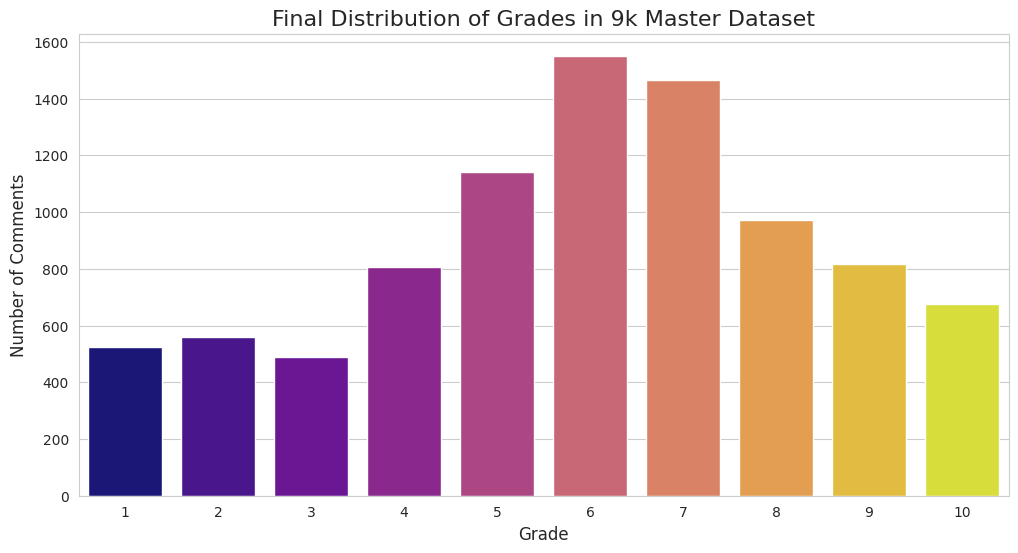

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# Mount Drive and load the final dataset
print("Mounting Google Drive...")
drive.mount('/content/drive', force_remount=True)
file_path = '/content/drive/MyDrive/Colab Notebooks/final_master_dataset_9k.csv'

try:
    print(f"Loading data from: {file_path}")
    df_final = pd.read_csv(file_path)

    # --- Create the Bar Chart (Count Plot) ---
    print("\n--- Generating Bar Chart for Grade Distribution ---")
    sns.set_style("whitegrid")
    plt.figure(figsize=(12, 6))

    # Round the grades to the nearest integer for clear counting, then sort by grade
    df_final['grade_rounded'] = df_final['grade'].round().astype(int)
    grade_order = sorted(df_final['grade_rounded'].unique())

    sns.countplot(x='grade_rounded', data=df_final, palette='plasma', order=grade_order, hue='grade_rounded', dodge=False, legend=False)

    plt.title('Final Distribution of Grades in 9k Master Dataset', fontsize=16)
    plt.xlabel('Grade', fontsize=12)
    plt.ylabel('Number of Comments', fontsize=12)
    plt.show()

except Exception as e:
    print(f"\n--- An error occurred: {e} ---")